In [1]:
!pip install pyTMD timescale xarray
import numpy as np
import pyTMD
import timescale
import xarray as xr
import matplotlib.pyplot as plt



c:\Users\apper\tudelft-conda\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
# 1. Tidal constants (amplitudes in m, phases in degrees)
constituents_list = ["O1", "K1"]
amplitudes = [0.167, 0.157]
phases = [21.2, 35.8]

# 2. Package constants into an xarray Dataset for pyTMD: amp * exp(-i*phase)
hc = np.asarray(amplitudes) * np.exp(-1j * np.radians(phases))
ds = xr.Dataset(
    {c.lower(): ((), hc[k], {"units": "m"}) for k, c in enumerate(constituents_list)}
)

# 3. Predict Aug-Nov for 30 years (2026-2055), every 10 min, in local time
# Local time = fixed UTC-6 
import pandas as pd

LOCAL_TZ = "Etc/GMT+6"


def predict_tide(times_local):
    """Tide height (m) at the given naive local times."""
    times_utc = times_local.tz_localize(LOCAL_TZ).tz_convert("UTC").tz_localize(None)
    ts = timescale.time.Timescale.from_datetime(times_utc.values)
    h = pyTMD.predict.time_series(ts.tide, ds, deltat=ts.tt_ut1, corrections="OTIS")
    h = h + pyTMD.predict.infer_minor(ts.tide, ds, deltat=ts.tt_ut1, corrections="OTIS")
    return np.asarray(h)


tpred = {}  
for i in range(30):
    year = 2026 + i
    times = pd.date_range(f"{year}-08-01 00:00", f"{year}-11-30 23:50", freq="10min")
    tpred[year] = pd.Series(predict_tide(times), index=times, name="tide_m")


print(tpred[2026].head().to_string(index=True, float_format="%.3f"))

2026-08-01 00:00:00   -0.111
2026-08-01 00:10:00   -0.109
2026-08-01 00:20:00   -0.107
2026-08-01 00:30:00   -0.105
2026-08-01 00:40:00   -0.102
Freq: 10min


time   n_days  rising%  falling%  above%  below%
05:30    3660     20.3      79.7    65.9    34.1
06:00    3660     18.3      81.7    62.3    37.7
06:30    3660     16.8      83.2    58.4    41.6
07:00    3660     16.0      84.0    54.6    45.4
07:30    3660     15.6      84.4    50.6    49.4
08:00    3660     15.9      84.1    46.7    53.3
08:30    3660     16.4      83.6    43.0    57.0
09:00    3660     17.7      82.3    38.9    61.1
09:30    3660     19.6      80.4    35.4    64.6
10:00    3660     22.0      78.0    32.0    68.0
10:30    3660     24.9      75.1    28.8    71.2
11:00    3660     28.3      71.7    26.0    74.0
11:30    3660     32.2      67.8    23.5    76.5
12:00    3660     36.3      63.7    21.9    78.1
12:30    3660     40.4      59.6    20.7    79.3
13:00    3660     44.8      55.2    19.9    80.1
13:30    3660     49.3      50.7    19.8    80.2
14:00    3660     53.7      46.3    19.9    80.1
14:30    3660     58.1      41.9    20.5    79.5
15:00    3660     62

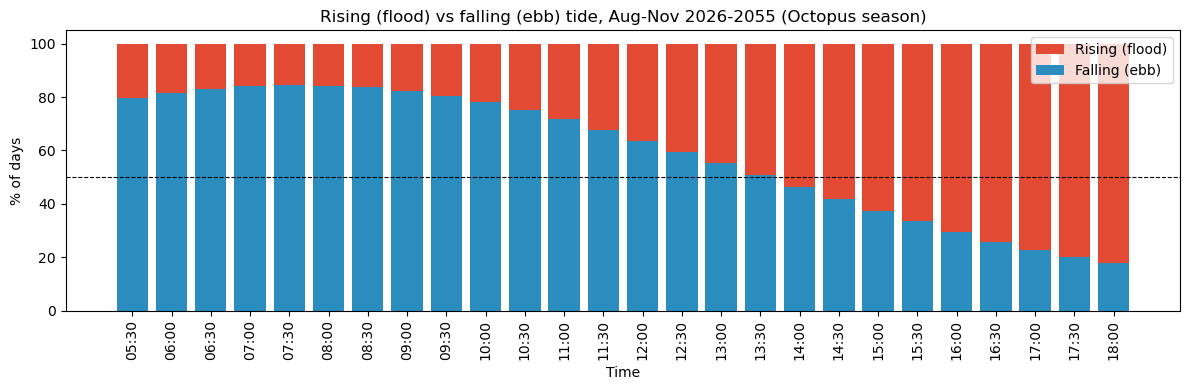

In [3]:
# For each time of day between 05:30 and 18:00 (local time, UTC-6), count over all days


# 1. Make the list of times: "05:30", "06:00", "06:30", ..., "18:00"
time_steps = []
minutes = 5 * 60 + 30            # 05:30 written in minutes
while minutes <= 18 * 60:        # stop at 18:00
    hour = minutes // 60
    minute = minutes % 60
    time_steps.append(f"{hour:02d}:{minute:02d}")
    minutes = minutes + 30

# 2. Start a counter at 0 for every time
n_days = {}
n_rising = {}
n_above = {}
for t in time_steps:
    n_days[t] = 0
    n_rising[t] = 0
    n_above[t] = 0

# 3. Go through every year and every data point
for year in tpred:
    heights = tpred[year].values
    times = tpred[year].index

    # skip the first and last point (they have no neighbour on one side)
    for i in range(1, len(heights) - 1):
        t = times[i].strftime("%H:%M")
        if t not in n_days:
            continue                      # not a time we care about

        n_days[t] = n_days[t] + 1

        # rising if the next value is higher than the previous one
        if heights[i + 1] > heights[i - 1]:
            n_rising[t] = n_rising[t] + 1

        # above mean sea level if height > 0
        if heights[i] > 0:
            n_above[t] = n_above[t] + 1

# 4. Turn the counts into percentages and print a table
rising_pct = []
falling_pct = []
print("time   n_days  rising%  falling%  above%  below%")
for t in time_steps:
    rise = 100 * n_rising[t] / n_days[t]
    above = 100 * n_above[t] / n_days[t]
    rising_pct.append(rise)
    falling_pct.append(100 - rise)
    print(f"{t}  {n_days[t]:6d}  {rise:7.1f}  {100 - rise:8.1f}  {above:6.1f}  {100 - above:6.1f}")

# 5. Bar chart: blue = falling at the bottom, red = rising stacked on top
plt.figure(figsize=(12, 4))
plt.bar(time_steps, falling_pct, color="#2b8cbe", label="Falling (ebb)")
plt.bar(time_steps, rising_pct, bottom=falling_pct, color="#e34a33", label="Rising (flood)")
plt.axhline(50, color="k", lw=0.8, ls="--")
plt.xticks(rotation=90)
plt.ylabel("% of days")
plt.xlabel("Time")
plt.title("Rising (flood) vs falling (ebb) tide, Aug-Nov 2026-2055 (Octopus season)")
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1], loc="upper right")
plt.tight_layout()
plt.show()


NameError: name 'obs' is not defined

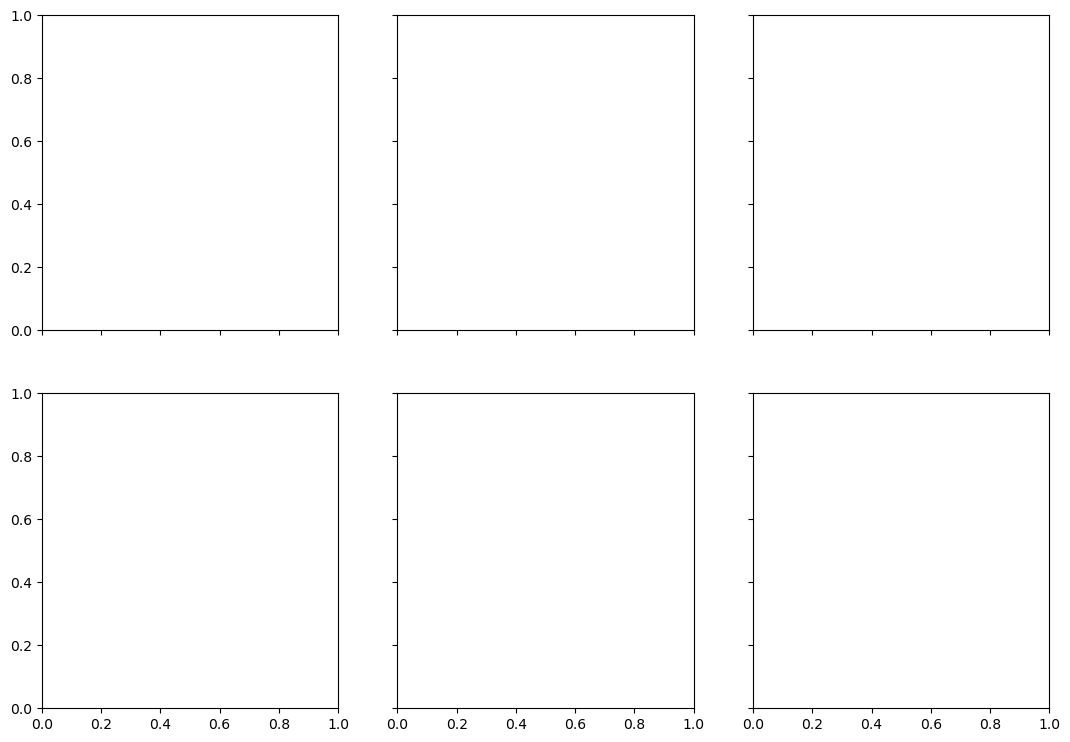

In [4]:
# Plot b) for each year 2021-2026, octopus season only (Aug-Nov): model vs CICESE scatter
# (uses obs and mod from the validation cell above)
years = range(2021, 2027)
lim = [-0.7, 0.7]

fig, axes = plt.subplots(2, 3, figsize=(13, 9), sharex=True, sharey=True)

for ax, year in zip(axes.flat, years):
    t0, t1 = f"{year}-08-01", f"{year}-11-30 23:59"
    o, m = obs[t0:t1], mod[t0:t1]
    r_year = np.corrcoef(o, m)[0, 1]
    rmse_year = np.sqrt(np.mean((m - o) ** 2)) * 100

    ax.plot(o, m, ".", ms=2, color="#2b8cbe", alpha=0.4)
    ax.plot(lim, lim, "k", lw=0.8)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_title(f"Aug-Nov {year}, r = {r_year:.2f}", fontsize=10)

for ax in axes[-1, :]:
    ax.set_xlabel("CICESE (m)")
for ax in axes[:, 0]:
    ax.set_ylabel("Model (m)")

plt.tight_layout()
plt.show()